# Model Calibration and Uncertainty

A classifier that predicts "70% chance" should be right about 70% of the time among all cases where
it says 70%. Many strong classifiers are **discriminative** but poorly **calibrated**: they rank
cases well while their probabilities are too extreme. This matters when probabilities drive decisions,
costs, or risk communication.

## Learning objectives

By the end of this notebook you can:

- distinguish discrimination from calibration;
- draw and interpret reliability diagrams;
- compute Brier score, log loss, and expected calibration error (ECE);
- calibrate classifiers with sigmoid and isotonic methods;
- choose decision thresholds from costs rather than accuracy alone;
- quantify uncertainty in evaluation metrics with the bootstrap.

## 1. Discrimination vs calibration

- **Discrimination** is the ability to separate positives from negatives (ROC AUC, ranking).
- **Calibration** is agreement between predicted probabilities and observed frequencies.

A model can have excellent AUC and terrible calibration. A model can also be perfectly calibrated
while having weak discrimination. For decisions that use probability thresholds or expected costs,
calibration is essential.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score

np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(42)

## 2. Data and models

We use a synthetic binary classification problem with 5,000 examples and a moderate signal-to-noise
ratio. The data is split into training and test sets. Calibration is fitted only on the training set
to avoid leakage.

In [2]:
X, y = make_classification(
    n_samples=5000,
    n_features=12,
    n_informative=6,
    n_redundant=2,
    n_clusters_per_class=2,
    class_sep=0.9,
    flip_y=0.03,
    random_state=42,
)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.35, stratify=y, random_state=42
)

print("train shape:", X_train.shape)
print("test shape: ", X_test.shape)
print("positive rate, train:", round(y_train.mean(), 3))
print("positive rate, test: ", round(y_test.mean(), 3))

train shape: (3250, 12)
test shape:  (1750, 12)
positive rate, train: 0.499
positive rate, test:  0.499


In [3]:
models = {
    "Logistic regression": LogisticRegression(max_iter=2000),
    "Random forest": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=8, random_state=42, n_jobs=-1
    ),
}

for name, model in models.items():
    model.fit(X_train, y_train)

rf = models["Random forest"]
cal_sigmoid = CalibratedClassifierCV(rf, method="sigmoid", cv=5).fit(X_train, y_train)
cal_isotonic = CalibratedClassifierCV(rf, method="isotonic", cv=5).fit(X_train, y_train)

## 3. Reliability diagrams

A reliability diagram bins predictions by confidence and plots the observed positive rate in each bin
against the mean predicted probability. Perfect calibration lies on the diagonal.

We also compute:

- **Brier score:** mean squared error of probabilities, lower is better;
- **log loss:** negative log-likelihood, punishes confident mistakes;
- **ECE:** weighted average gap between confidence and accuracy across bins.

In [4]:
def expected_calibration_error(y_true, prob, n_bins=10):
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    bin_ids = np.digitize(prob, bins[1:-1], right=True)
    ece = 0.0
    for b in range(n_bins):
        mask = bin_ids == b
        if mask.sum() > 0:
            confidence = prob[mask].mean()
            accuracy = y_true[mask].mean()
            ece += (mask.sum() / len(prob)) * abs(accuracy - confidence)
    return ece

def evaluate(name, model):
    prob = model.predict_proba(X_test)[:, 1]
    return {
        "model": name,
        "AUC": roc_auc_score(y_test, prob),
        "Brier": brier_score_loss(y_test, prob),
        "Log loss": log_loss(y_test, prob),
        "ECE": expected_calibration_error(y_test, prob),
    }

results = pd.DataFrame([
    evaluate("Logistic regression", models["Logistic regression"]),
    evaluate("Random forest", rf),
    evaluate("RF + sigmoid", cal_sigmoid),
    evaluate("RF + isotonic", cal_isotonic),
])
print(results.round(4).to_string(index=False))

              model    AUC  Brier  Log loss    ECE
Logistic regression 0.8393 0.1623    0.4994 0.0524
      Random forest 0.9447 0.1020    0.3412 0.0800
       RF + sigmoid 0.9405 0.0992    0.3188 0.0392
      RF + isotonic 0.9407 0.0981    0.3479 0.0210


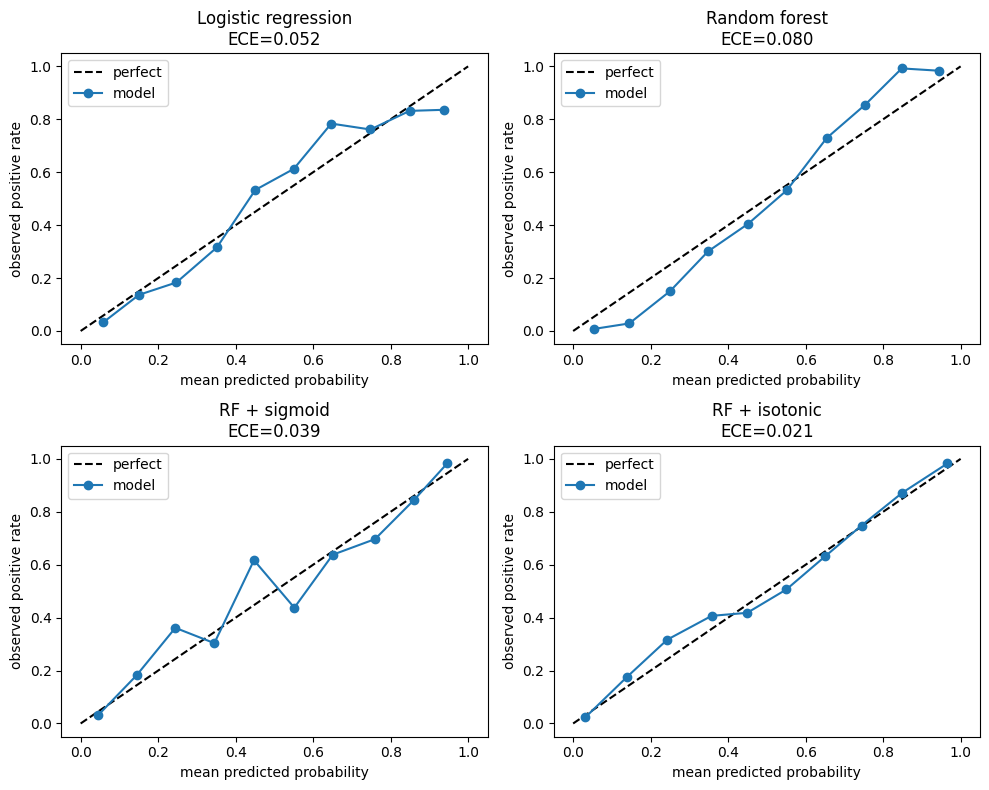

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, (name, model) in zip(axes.ravel(), [
    ("Logistic regression", models["Logistic regression"]),
    ("Random forest", rf),
    ("RF + sigmoid", cal_sigmoid),
    ("RF + isotonic", cal_isotonic),
]):
    prob = model.predict_proba(X_test)[:, 1]
    frac_pos, mean_pred = calibration_curve(
        y_test, prob, n_bins=10, strategy="uniform"
    )
    ax.plot([0, 1], [0, 1], "k--", label="perfect")
    ax.plot(mean_pred, frac_pos, marker="o", label="model")
    ax.set_xlabel("mean predicted probability")
    ax.set_ylabel("observed positive rate")
    ax.set_title(f"{name}\nECE={expected_calibration_error(y_test, prob):.3f}")
    ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

The random forest often looks overconfident: its probabilities pile up near 0 and 1 while the observed
frequency is less extreme. Sigmoid calibration fits a one-dimensional logistic correction; isotonic
calibration fits a flexible monotone step function. Isotonic is more expressive but needs more data
and can overfit small calibration sets.

## 4. Calibration does not change ranking

Sigmoid calibration applies a monotone transformation to the probabilities. It changes the probability
values without changing the order of examples, so AUC is essentially unchanged. Brier score, log loss,
and ECE improve because the probabilities are more honest.

                        AUC   Brier  Log loss     ECE
model                                                
Logistic regression  0.8393  0.1623    0.4994  0.0524
Random forest        0.9447  0.1020    0.3412  0.0800
RF + sigmoid         0.9405  0.0992    0.3188  0.0392
RF + isotonic        0.9407  0.0981    0.3479  0.0210


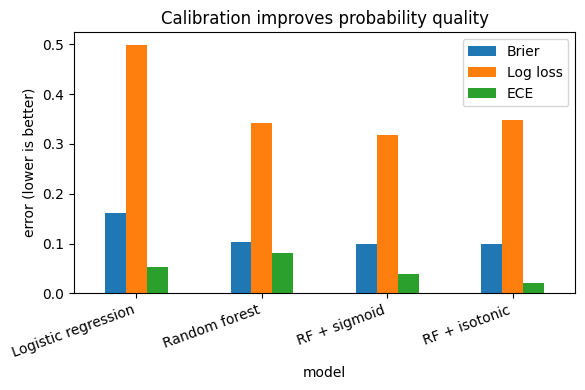

In [6]:
comparison = results.set_index("model")[["AUC", "Brier", "Log loss", "ECE"]]
print(comparison.round(4))

plt.figure(figsize=(6, 4))
comparison[["Brier", "Log loss", "ECE"]].plot(kind="bar", ax=plt.gca())
plt.ylabel("error (lower is better)")
plt.title("Calibration improves probability quality")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

## 5. Decision thresholds and costs

A probability is not a decision. To act, we choose a threshold. If a false negative is five times
more costly than a false positive, the optimal threshold is lower than 0.5. Calibration lets us use
the predicted probability directly in an expected-cost calculation:

$$ E[\text{cost}] = P(\hat{y}=1 \mid x) \cdot C_{FP} +
(1 - P(\hat{y}=1 \mid x)) \cdot C_{FN} $$

for the decision to predict positive, compared with the cost of predicting negative.

Random forest: best threshold=0.28, cost=0.239


RF + isotonic: best threshold=0.14, cost=0.255


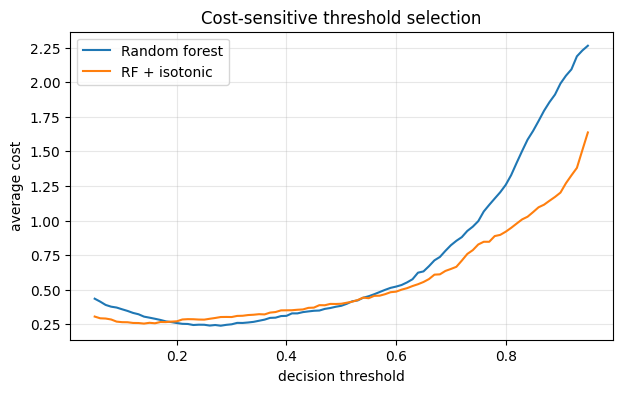

In [7]:
cost_fp = 1.0
cost_fn = 5.0

def total_cost(y_true, prob, threshold):
    pred = (prob >= threshold).astype(int)
    fp = np.sum((pred == 1) & (y_true == 0))
    fn = np.sum((pred == 0) & (y_true == 1))
    return (fp * cost_fp + fn * cost_fn) / len(y_true)

thresholds = np.linspace(0.05, 0.95, 91)
for name, model in [
    ("Random forest", rf),
    ("RF + isotonic", cal_isotonic),
]:
    prob = model.predict_proba(X_test)[:, 1]
    costs = [total_cost(y_test, prob, t) for t in thresholds]
    best_idx = int(np.argmin(costs))
    print(f"{name}: best threshold={thresholds[best_idx]:.2f}, "
          f"cost={costs[best_idx]:.3f}")

plt.figure(figsize=(7, 4))
for name, model in [
    ("Random forest", rf),
    ("RF + isotonic", cal_isotonic),
]:
    prob = model.predict_proba(X_test)[:, 1]
    costs = [total_cost(y_test, prob, t) for t in thresholds]
    plt.plot(thresholds, costs, label=name)
plt.xlabel("decision threshold")
plt.ylabel("average cost")
plt.title("Cost-sensitive threshold selection")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

A calibrated model can be used with a threshold derived from costs. An uncalibrated model can still be
used if the threshold is tuned on validation data, but the probability itself should not be
interpreted as a risk without calibration.

## 6. Bootstrap uncertainty

Metrics are estimates from a finite test set. The bootstrap resamples the test set with replacement to
approximate the sampling distribution of a metric. This is a simple way to report uncertainty without
strong distributional assumptions.

In [8]:
def bootstrap_ci(y_true, prob, metric_fn, n_boot=1000, seed=0):
    local_rng = np.random.default_rng(seed)
    values = []
    n = len(y_true)
    for _ in range(n_boot):
        idx = local_rng.integers(0, n, n)
        values.append(metric_fn(y_true[idx], prob[idx]))
    return np.percentile(values, [2.5, 97.5])

for name, model in [("Random forest", rf), ("RF + isotonic", cal_isotonic)]:
    prob = model.predict_proba(X_test)[:, 1]
    ci = bootstrap_ci(y_test, prob, brier_score_loss)
    print(f"{name} Brier 95% bootstrap CI: {np.round(ci, 4)}")

Random forest Brier 95% bootstrap CI: [0.0951 0.1087]


RF + isotonic Brier 95% bootstrap CI: [0.0892 0.1068]


The bootstrap interval reflects test-set sampling variability, not model-selection uncertainty or
distribution shift. For a complete uncertainty report, combine calibration, bootstrap intervals, and
an analysis of the data collection process.

## 7. Summary

- Discrimination and calibration are different properties; AUC alone does not measure calibration.
- Reliability diagrams compare predicted probabilities with observed frequencies.
- Brier score, log loss, and ECE quantify probability quality.
- Sigmoid and isotonic calibration are post-hoc corrections fitted on held-out or cross-validated data.
- Cost-sensitive decisions need thresholds based on costs, not just 0.5.
- Bootstrap intervals quantify evaluation uncertainty.

## Exercises

1. Repeat the experiment with 200 training examples. Which calibration method is more stable?
2. Add a Gaussian Naive Bayes model and compare its calibration with the random forest.
3. Change the false-negative cost to 20 and find the new optimal threshold.
4. Plot the distribution of predicted probabilities for the uncalibrated and calibrated models.
5. Explain why isotonic calibration can overfit when the calibration set is small.